In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

RANDOM_STATE = 42

In [3]:
DATA_PATH = Path("HR-Employee-Attrition.csv")

df = pd.read_csv(DATA_PATH)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1470
Number of columns: 35


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

Dataset shape: (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Last 5 rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [5]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    "Unique_Values": df.nunique()
})

display(
    missing_summary.sort_values(
        by="Missing_Count",
        ascending=False
    )
)

print("Exact duplicate rows:", df.duplicated().sum())

,Missing_Count,Missing_Percentage,Unique_Values
Age,0,0.0,43
Attrition,0,0.0,2
BusinessTravel,0,0.0,3
DailyRate,0,0.0,886
Department,0,0.0,3
DistanceFromHome,0,0.0,29
Education,0,0.0,5
EducationField,0,0.0,6
EmployeeCount,0,0.0,1
EmployeeNumber,0,0.0,1470


Exact duplicate rows: 0


Attrition counts:


Attrition
No     1233
Yes     237
Name: count, dtype: int64


Attrition percentages:


Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

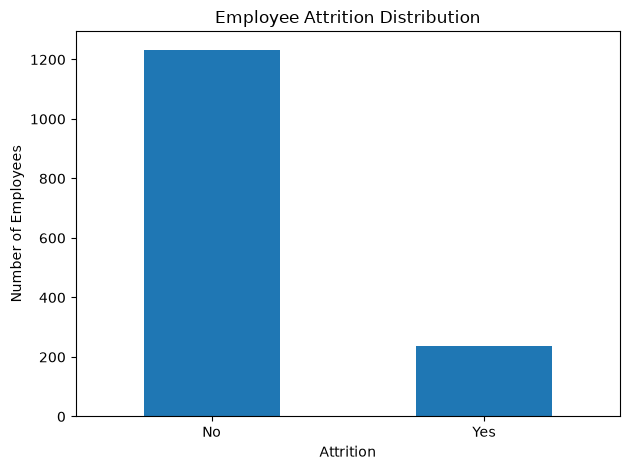

In [6]:
if "Attrition" not in df.columns:
    raise ValueError("The target column 'Attrition' is missing.")

print("Attrition counts:")
display(df["Attrition"].value_counts())

print("\nAttrition percentages:")
display(
    (df["Attrition"].value_counts(normalize=True) * 100)
    .round(2)
)

df["Attrition"].value_counts().plot(
    kind="bar",
    rot=0
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

In [7]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant columns:")
print(constant_columns)

possible_identifiers = [
    col for col in ["EmployeeNumber", "EmployeeCount", "Over18",
                    "StandardHours"]
    if col in df.columns
]

print("\nColumns to investigate:")
print(possible_identifiers)

Constant columns:
['EmployeeCount', 'Over18', 'StandardHours']

Columns to investigate:
['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']


In [8]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical columns:", len(categorical_columns))
print(categorical_columns)

print("\nNumerical columns:", len(numerical_columns))
print(numerical_columns)

print("\nNumerical summary:")
display(df[numerical_columns].describe().T)

Categorical columns: 9
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

Numerical columns: 26
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Numerical summary:


C:\Users\ads2609025\AppData\Local\Temp\1\ipykernel_11324\4073067194.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [9]:
# Target variable
y = df["Attrition"]

# Remove target and non-informative columns from features
columns_to_drop = [
    "Attrition",
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

X = df.drop(columns=columns_to_drop, errors="ignore")

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

Feature matrix shape: (1470, 30)
Target shape: (1470,)

Target distribution:


Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining attrition distribution:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting attrition distribution:")
display(y_test.value_counts(normalize=True).round(3))

Training samples: 1176
Testing samples: 294

Training attrition distribution:


Attrition
No     0.838
Yes    0.162
Name: proportion, dtype: float64


Testing attrition distribution:


Attrition
No     0.84
Yes    0.16
Name: proportion, dtype: float64

In [11]:
# Convert categorical columns into numerical indicator columns
X_train_encoded = pd.get_dummies(X_train, dtype=int)
X_test_encoded = pd.get_dummies(X_test, dtype=int)

# Ensure both datasets have identical feature columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

print("\nExample encoded features:")
display(X_train_encoded.head())

Encoded training shape: (1176, 51)
Encoded testing shape: (294, 51)

Example encoded features:


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,OverTime_No,OverTime_Yes
1194,47,1225,2,4,2,47,4,4,2,15972,...,0,0,0,0,0,1,0,0,1,0
128,22,594,2,1,3,100,3,1,4,2523,...,0,0,0,0,0,0,1,0,1,0
810,46,406,3,1,1,52,3,4,3,17465,...,0,0,0,0,0,0,1,0,1,0
478,25,622,13,1,2,40,3,1,3,2096,...,0,0,0,0,1,0,1,0,1,0
491,43,1001,9,5,4,72,3,2,3,5679,...,0,0,0,0,0,1,0,0,0,1


In [12]:
def bootstrap_sample(X, y, random_state=None):
    """
    Generate one bootstrap sample by sampling rows with replacement.

    Returns:
        X_bootstrap: sampled feature rows
        y_bootstrap: sampled target labels
        sampled_indices: original positional indices selected
        oob_indices: positional indices never selected
    """
    rng = np.random.default_rng(random_state)

    n_samples = len(X)

    # Draw n_samples indices with replacement
    sampled_indices = rng.choice(
        n_samples,
        size=n_samples,
        replace=True
    )

    # Find unique observations selected at least once
    unique_indices = np.unique(sampled_indices)

    # Observations never selected belong to the OOB set
    all_indices = np.arange(n_samples)
    oob_indices = np.setdiff1d(
        all_indices,
        unique_indices
    )

    X_bootstrap = X.iloc[sampled_indices].reset_index(drop=True)
    y_bootstrap = y.iloc[sampled_indices].reset_index(drop=True)

    return (
        X_bootstrap,
        y_bootstrap,
        sampled_indices,
        oob_indices
    )


# Test the function with one bootstrap sample
X_boot, y_boot, sampled_idx, oob_idx = bootstrap_sample(
    X_train_encoded,
    y_train,
    random_state=42
)

print("Original training rows:", len(X_train_encoded))
print("Bootstrap draws:", len(X_boot))
print("Unique observations:", len(np.unique(sampled_idx)))
print("OOB observations:", len(oob_idx))

print(
    "Unique percentage:",
    round(len(np.unique(sampled_idx)) / len(X_train_encoded) * 100, 2),
    "%"
)

print(
    "OOB percentage:",
    round(len(oob_idx) / len(X_train_encoded) * 100, 2),
    "%"
)

Original training rows: 1176
Bootstrap draws: 1176
Unique observations: 745
OOB observations: 431
Unique percentage: 63.35 %
OOB percentage: 36.65 %


In [13]:
N_BOOTSTRAPS = 5

bootstrap_samples = []
bootstrap_targets = []
bootstrap_indices = []
oob_indices_list = []

for i in range(N_BOOTSTRAPS):
    X_boot, y_boot, sampled_idx, oob_idx = bootstrap_sample(
        X_train_encoded,
        y_train,
        random_state=42 + i
    )

    bootstrap_samples.append(X_boot)
    bootstrap_targets.append(y_boot)
    bootstrap_indices.append(sampled_idx)
    oob_indices_list.append(oob_idx)

print("Created", len(bootstrap_samples), "bootstrap samples.")

Created 5 bootstrap samples.


In [14]:
bootstrap_results = []

n_train = len(X_train_encoded)

for i in range(N_BOOTSTRAPS):
    sampled_idx = bootstrap_indices[i]
    oob_idx = oob_indices_list[i]

    unique_count = len(np.unique(sampled_idx))
    oob_count = len(oob_idx)

    bootstrap_results.append({
        "Bootstrap": i + 1,
        "Total_Draws": len(sampled_idx),
        "Unique_Observations": unique_count,
        "Unique_Percentage": round(
            unique_count / n_train * 100, 2
        ),
        "OOB_Observations": oob_count,
        "OOB_Percentage": round(
            oob_count / n_train * 100, 2
        )
    })

bootstrap_results_df = pd.DataFrame(bootstrap_results)

display(bootstrap_results_df)

print(
    "Theoretical unique percentage:",
    round((1 - (1 - 1 / n_train) ** n_train) * 100, 2),
    "%"
)

print(
    "Theoretical OOB percentage:",
    round(((1 - 1 / n_train) ** n_train) * 100, 2),
    "%"
)

,Bootstrap,Total_Draws,Unique_Observations,Unique_Percentage,OOB_Observations,OOB_Percentage
0,1,1176,745,63.35,431,36.65
1,2,1176,741,63.01,435,36.99
2,3,1176,752,63.95,424,36.05
3,4,1176,751,63.86,425,36.14
4,5,1176,765,65.05,411,34.95


Theoretical unique percentage: 63.23 %
Theoretical OOB percentage: 36.77 %


In [15]:
decision_trees = []

for i in range(N_BOOTSTRAPS):
    tree = DecisionTreeClassifier(
        random_state=100 + i
    )

    tree.fit(
        bootstrap_samples[i],
        bootstrap_targets[i]
    )

    decision_trees.append(tree)

    print(f"Decision Tree {i + 1} trained successfully.")

print("\nTotal trees trained:", len(decision_trees))

Decision Tree 1 trained successfully.
Decision Tree 2 trained successfully.
Decision Tree 3 trained successfully.
Decision Tree 4 trained successfully.
Decision Tree 5 trained successfully.

Total trees trained: 5


In [16]:
individual_results = []
individual_predictions = []

for i, tree in enumerate(decision_trees):
    y_pred = tree.predict(X_test_encoded)

    individual_predictions.append(y_pred)

    individual_results.append({
        "Model": f"Decision Tree {i + 1}",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Attrition_Yes_F1": f1_score(
            y_test,
            y_pred,
            pos_label="Yes",
            zero_division=0
        )
    })

individual_results_df = pd.DataFrame(individual_results)

display(
    individual_results_df.round(4)
)

,Model,Accuracy,Attrition_Yes_F1
0,Decision Tree 1,0.7721,0.3232
1,Decision Tree 2,0.7857,0.2759
2,Decision Tree 3,0.7755,0.3265
3,Decision Tree 4,0.7891,0.3542
4,Decision Tree 5,0.7415,0.2245


In [17]:
def majority_vote(predictions):
    """
    Combine predictions from multiple classifiers using majority voting.

    predictions: 2D array with shape
                 (number_of_trees, number_of_observations)
    """
    predictions = np.asarray(predictions)

    if predictions.ndim != 2:
        raise ValueError("Predictions must be a 2D array.")

    final_predictions = []

    for observation_predictions in predictions.T:
        classes, counts = np.unique(
            observation_predictions,
            return_counts=True
        )

        # np.unique sorts labels; ties are resolved consistently
        # by selecting the first class among those with max votes.
        winner = classes[np.argmax(counts)]

        final_predictions.append(winner)

    return np.array(final_predictions)


# Stack the predictions from all five trees
all_predictions = np.vstack(individual_predictions)

print("Prediction matrix shape:", all_predictions.shape)

Prediction matrix shape: (5, 294)


In [18]:
y_ensemble_pred = majority_vote(all_predictions)

print("Ensemble predictions generated.")

print("\nFirst 20 predictions:")
print(y_ensemble_pred[:20])

print("\nActual labels:")
print(y_test.to_numpy()[:20])

Ensemble predictions generated.

First 20 predictions:
['Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No'
 'No' 'No' 'No' 'No' 'No' 'No']

Actual labels:
['No' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No'
 'No' 'No' 'No' 'No' 'No' 'No']


In [19]:
ensemble_result = pd.DataFrame([{
    "Model": "Bagged Ensemble (5 Trees)",
    "Accuracy": accuracy_score(y_test, y_ensemble_pred),
    "Attrition_Yes_F1": f1_score(
        y_test,
        y_ensemble_pred,
        pos_label="Yes",
        zero_division=0
    )
}])

comparison = pd.concat(
    [individual_results_df, ensemble_result],
    ignore_index=True
)

display(
    comparison.round(4).sort_values(
        by="Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Attrition_Yes_F1
5,Bagged Ensemble (5 Trees),0.8231,0.3333
3,Decision Tree 4,0.7891,0.3542
1,Decision Tree 2,0.7857,0.2759
2,Decision Tree 3,0.7755,0.3265
0,Decision Tree 1,0.7721,0.3232
4,Decision Tree 5,0.7415,0.2245


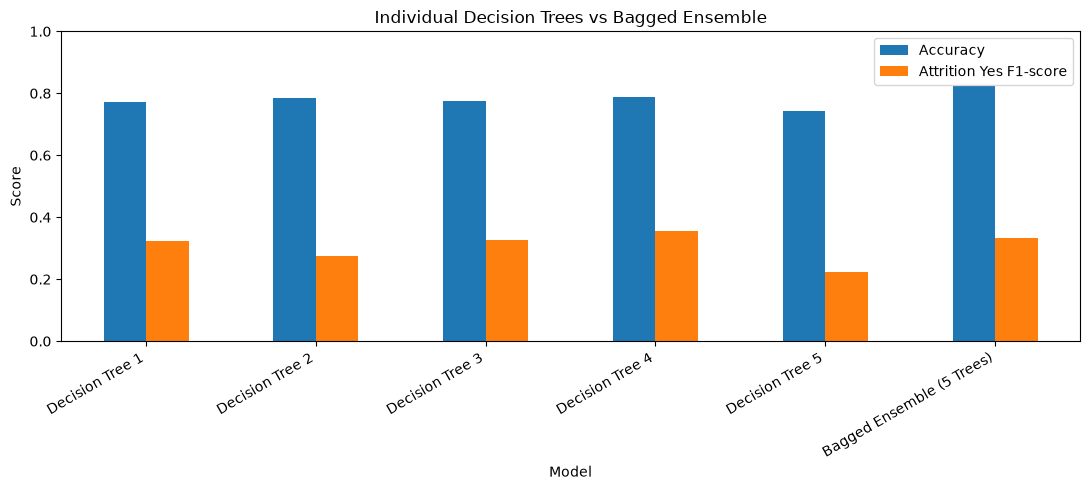

In [20]:
comparison_plot = comparison.set_index("Model")

comparison_plot[["Accuracy", "Attrition_Yes_F1"]].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Individual Decision Trees vs Bagged Ensemble")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(["Accuracy", "Attrition Yes F1-score"])
plt.tight_layout()
plt.show()

Ensemble classification report:

              precision    recall  f1-score   support

          No       0.87      0.93      0.90       247
         Yes       0.42      0.28      0.33        47

    accuracy                           0.82       294
   macro avg       0.65      0.60      0.62       294
weighted avg       0.80      0.82      0.81       294



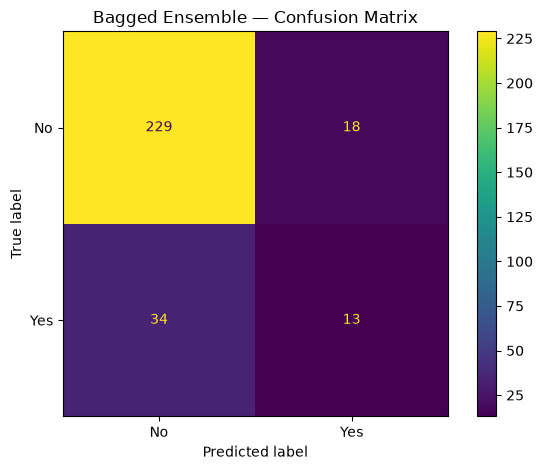

In [21]:
print("Ensemble classification report:\n")

print(
    classification_report(
        y_test,
        y_ensemble_pred,
        labels=["No", "Yes"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    y_ensemble_pred,
    labels=["No", "Yes"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot()

plt.title("Bagged Ensemble — Confusion Matrix")
plt.tight_layout()
plt.show()

In [22]:
feature_settings = {
    "Bagging (all features)": None,
    "Random Forest-style (sqrt)": "sqrt",
    "Random Forest-style (log2)": "log2"
}

feature_comparison_results = []
feature_predictions = {}

for setting_name, max_features in feature_settings.items():

    predictions = []

    for i in range(N_BOOTSTRAPS):
        tree = DecisionTreeClassifier(
            max_features=max_features,
            random_state=100 + i
        )

        tree.fit(
            bootstrap_samples[i],
            bootstrap_targets[i]
        )

        predictions.append(tree.predict(X_test_encoded))

    predictions = np.vstack(predictions)

    ensemble_pred = majority_vote(predictions)
    feature_predictions[setting_name] = ensemble_pred

    feature_comparison_results.append({
        "Strategy": setting_name,
        "Accuracy": accuracy_score(y_test, ensemble_pred),
        "Attrition_Yes_F1": f1_score(
            y_test,
            ensemble_pred,
            pos_label="Yes",
            zero_division=0
        )
    })

feature_comparison_df = pd.DataFrame(feature_comparison_results)

display(feature_comparison_df.round(4))

,Strategy,Accuracy,Attrition_Yes_F1
0,Bagging (all features),0.8231,0.3333
1,Random Forest-style (sqrt),0.8095,0.3488
2,Random Forest-style (log2),0.8401,0.3380


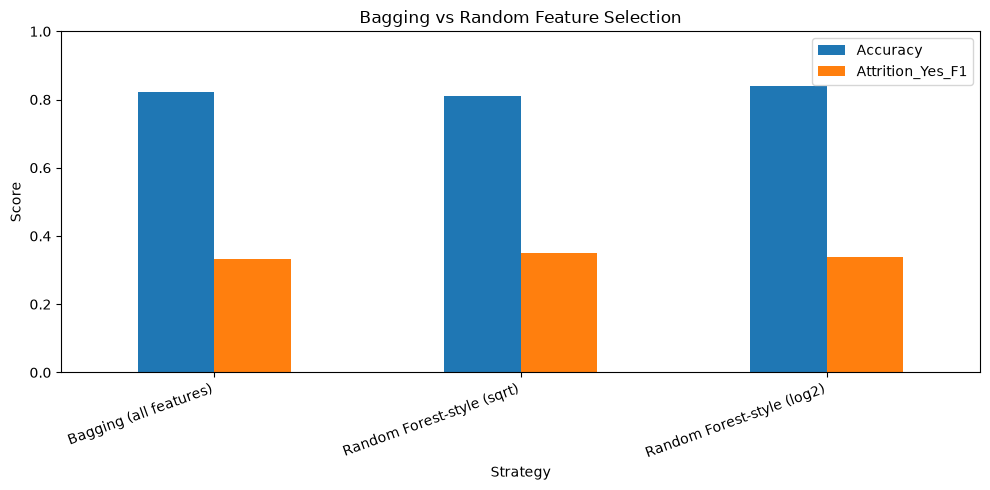

In [23]:
feature_comparison_df.set_index("Strategy")[
    ["Accuracy", "Attrition_Yes_F1"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Bagging vs Random Feature Selection")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_baseline = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train_encoded, y_train)

rf_baseline_pred = rf_baseline.predict(X_test_encoded)

print("Baseline Random Forest")
print("Accuracy:", round(
    accuracy_score(y_test, rf_baseline_pred), 4
))
print("Attrition Yes F1-score:", round(
    f1_score(
        y_test,
        rf_baseline_pred,
        pos_label="Yes",
        zero_division=0
    ), 4
))

Baseline Random Forest
Accuracy: 0.8503
Attrition Yes F1-score: 0.2414


In [25]:
tree_counts = [10, 25, 50, 100]
tree_count_results = []

for n_trees in tree_counts:

    rf = RandomForestClassifier(
        n_estimators=n_trees,
        max_depth=None,
        max_features="sqrt",
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train_encoded, y_train)
    predictions = rf.predict(X_test_encoded)

    tree_count_results.append({
        "Number_of_Trees": n_trees,
        "Accuracy": accuracy_score(y_test, predictions),
        "Attrition_Yes_F1": f1_score(
            y_test,
            predictions,
            pos_label="Yes",
            zero_division=0
        )
    })

tree_count_df = pd.DataFrame(tree_count_results)

display(tree_count_df.round(4))

,Number_of_Trees,Accuracy,Attrition_Yes_F1
0,10,0.8367,0.1724
1,25,0.8469,0.2857
2,50,0.8469,0.2373
3,100,0.8503,0.2414


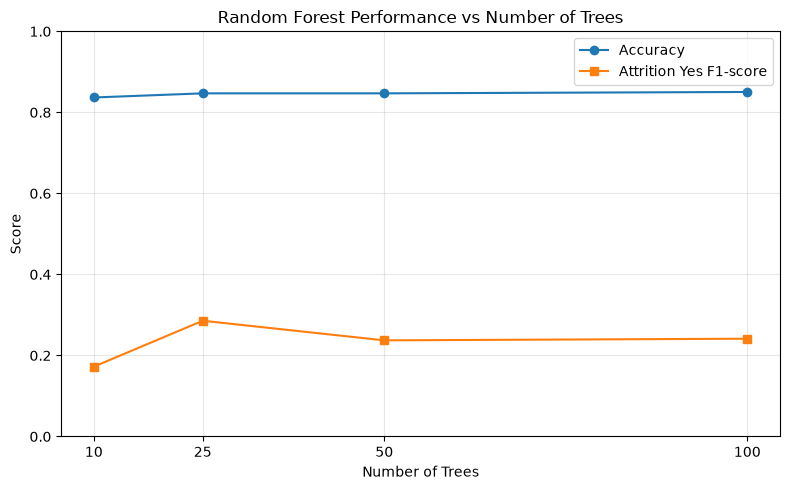

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    tree_count_df["Number_of_Trees"],
    tree_count_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    tree_count_df["Number_of_Trees"],
    tree_count_df["Attrition_Yes_F1"],
    marker="s",
    label="Attrition Yes F1-score"
)

plt.xlabel("Number of Trees")
plt.ylabel("Score")
plt.title("Random Forest Performance vs Number of Trees")
plt.xticks(tree_counts)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf = RandomForestClassifier(
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [None, 10, 20],
    "max_features": ["sqrt", "log2", None]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1
)

grid_search.fit(X_train_encoded, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:
{'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 50}

Best cross-validation F1-score:
nan


c:\Users\ads2609025\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(
c:\Users\ads2609025\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the train scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


In [28]:
best_rf = grid_search.best_estimator_

best_rf_pred = best_rf.predict(X_test_encoded)

print("Tuned Random Forest — Test Results")
print("Accuracy:", round(
    accuracy_score(y_test, best_rf_pred), 4
))
print("Attrition Yes F1-score:", round(
    f1_score(
        y_test,
        best_rf_pred,
        pos_label="Yes",
        zero_division=0
    ), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_rf_pred,
    labels=["No", "Yes"],
    zero_division=0
))

Tuned Random Forest — Test Results
Accuracy: 0.8469
Attrition Yes F1-score: 0.2373

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.98      0.91       247
         Yes       0.58      0.15      0.24        47

    accuracy                           0.85       294
   macro avg       0.72      0.56      0.58       294
weighted avg       0.81      0.85      0.81       294



In [29]:
from sklearn.metrics import make_scorer

attrition_f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

In [30]:
importance_df = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": best_rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 10 encoded features:")
display(importance_df.head(10).round(5))

Top 10 encoded features:


,Feature,Importance
0,MonthlyIncome,0.07464
1,TotalWorkingYears,0.06213
2,Age,0.06132
3,DailyRate,0.05511
4,MonthlyRate,0.04678
5,HourlyRate,0.04316
6,DistanceFromHome,0.04097
7,YearsWithCurrManager,0.03977
8,YearsAtCompany,0.03451
9,NumCompaniesWorked,0.03182


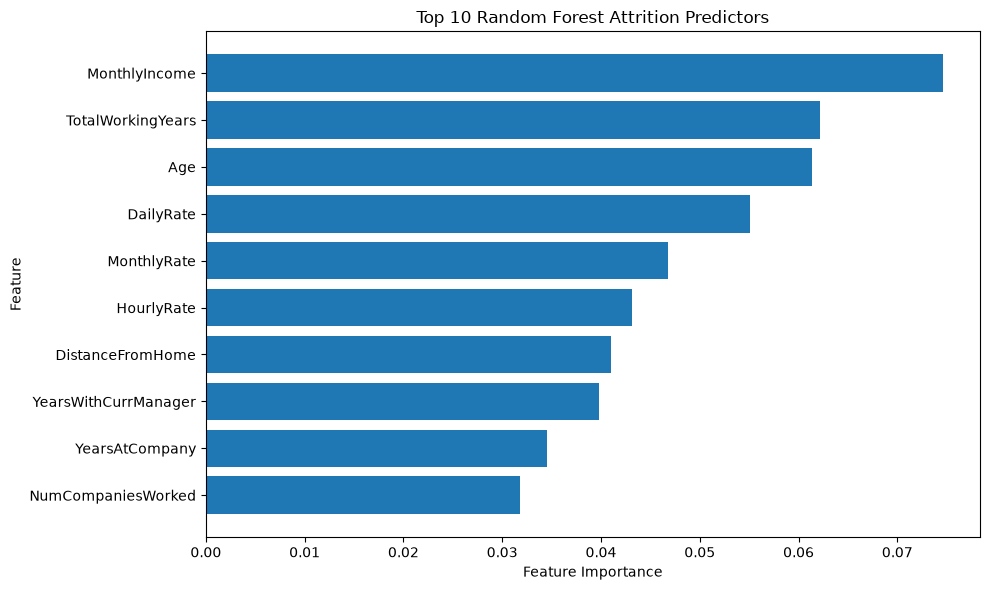

In [31]:
top_10 = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Feature"],
    top_10["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Attrition Predictors")
plt.tight_layout()
plt.show()

In [32]:
original_feature_importance = {}

for encoded_feature, importance in zip(
    X_train_encoded.columns,
    best_rf.feature_importances_
):
    original_feature = next(
        (
            col for col in X.columns
            if encoded_feature == col
            or encoded_feature.startswith(col + "_")
        ),
        encoded_feature
    )

    original_feature_importance[original_feature] = (
        original_feature_importance.get(original_feature, 0)
        + importance
    )

grouped_importance_df = pd.DataFrame({
    "Feature": list(original_feature_importance.keys()),
    "Importance": list(original_feature_importance.values())
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("Top 10 original features:")
display(grouped_importance_df.head(10).round(5))

Top 10 original features:


,Feature,Importance
0,MonthlyIncome,0.07464
1,TotalWorkingYears,0.06213
2,Age,0.06132
3,DailyRate,0.05511
4,OverTime,0.05305
5,JobRole,0.04788
6,MonthlyRate,0.04678
7,HourlyRate,0.04316
8,DistanceFromHome,0.04097
9,YearsWithCurrManager,0.03977


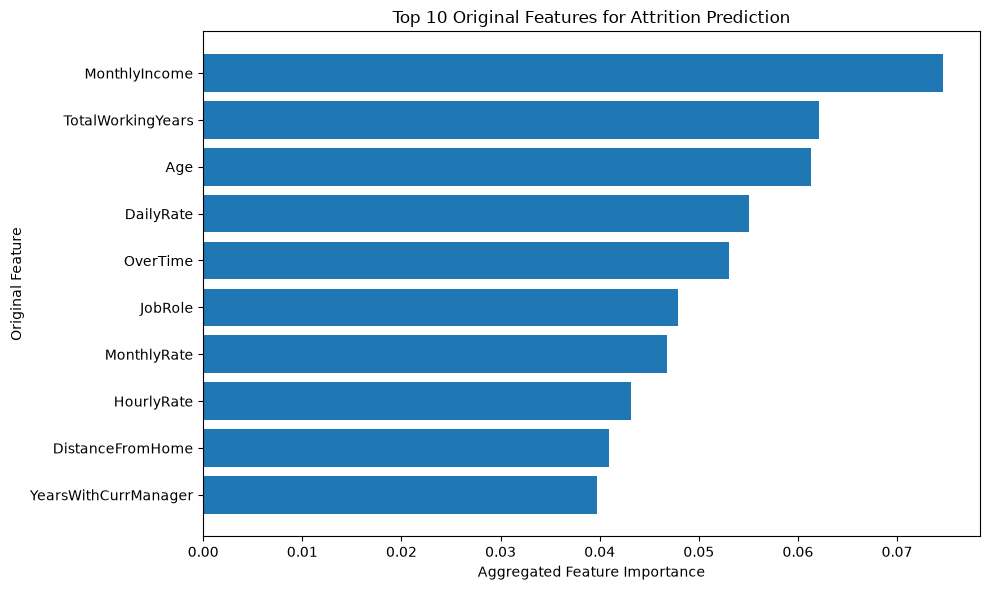

In [33]:
top_original = grouped_importance_df.head(10).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_original["Feature"],
    top_original["Importance"]
)

plt.xlabel("Aggregated Feature Importance")
plt.ylabel("Original Feature")
plt.title("Top 10 Original Features for Attrition Prediction")
plt.tight_layout()
plt.show()

In [34]:
print("TOP 10 ATTRITION PREDICTORS")
print("=" * 45)

for rank, row in grouped_importance_df.head(10).iterrows():
    print(
        f"{rank + 1}. {row['Feature']}: "
        f"{row['Importance']:.4f}"
    )

print("\nInterpretation:")
print("- Higher importance means greater contribution to tree splits.")
print("- Importance does not show whether attrition increases or decreases.")
print("- Feature importance does not establish causation.")
print("- Validate important predictors using additional analyses.")

TOP 10 ATTRITION PREDICTORS
1. MonthlyIncome: 0.0746
2. TotalWorkingYears: 0.0621
3. Age: 0.0613
4. DailyRate: 0.0551
5. OverTime: 0.0530
6. JobRole: 0.0479
7. MonthlyRate: 0.0468
8. HourlyRate: 0.0432
9. DistanceFromHome: 0.0410
10. YearsWithCurrManager: 0.0398

Interpretation:
- Higher importance means greater contribution to tree splits.
- Importance does not show whether attrition increases or decreases.
- Feature importance does not establish causation.
- Validate important predictors using additional analyses.
